In [3]:
import numpy as np
import matplotlib.pyplot as plt
PI = 3.1416

In [4]:
#Pressure from equation of state.
def pEqs(phi):
    return 2*phi/PI

#Pressure from virial theoretically
def pVirTh(phi):
    tmp1 = 2*phi/PI
    tmp2 = 1 + (4*phi*(1-0.5*phi))/((1-phi)**3)
    return tmp1*tmp2

#Pressure from the gr calculations.
def pVirSim(phi, gr):
    tmp1 = 2*phi/PI
    tmp2 = 1 + 4*phi*gr
    return tmp1*tmp2

In [5]:
#Verification from two definitions.
phi = 0.0010
print("From pEqs: ", pEqs(phi))
print("Form pVirTh: ", pVirTh(phi))
print("From pVirSim: ", pVirSim(phi,0.90814))

From pEqs:  0.0006366182836771072
Form pVirTh:  0.0006391711344716323
From pVirSim:  0.0006389308377896613


In [6]:
#### Calculating the mean values ####
#npart:100, nColl:400
tColl100 = np.array([208744,271095,288226, 287913,  200780, 287791, 220426,288298, 289810,288240 ])
tColl1000= np.array([30467894, 30646307,24815207,24623551, 24580062, 25061629,24252384,23004567,24138099,24713590 ])
tColl10000=np.array([861076825,946368602,934555043, 954491001, 938932997, 956148716])


In [7]:
################ Efficiency calculations of the code. #####################
npart = np.array([100, 1000, 10000])
nColl = np.array([10000,10000,100000 ])
nColl2 = np.array([400, 400, 100])
### Time in microseconds ###
totRunTime = np.array([81823112,507196405, 33132552702  ])
totRunTime2 = np.array([np.mean(tColl100), np.mean(tColl1000), np.mean(tColl10000)])

particlePropagateT = np.array([10512,188736,1.92338e+07 ])
ParticleToWallPropagateT = np.array([151643, 848375, 3.99132e+07 ])
pwCollTimeT = np.array([221033, 154511,965954  ])
ppCollTimeT = np.array([7.05478e+07,4.46762e+08, 2.9137e+10  ])
collTableUpdateT = np.array([8.02668e+07, 4.92762e+08,3.17436e+10 ])
velUpdateT = np.array([4135,3730, 46402 ])
calcKineticEneT = np.array([10433, 191947,2.04545e+07 ])


In [8]:
############## Plotting the data ###############

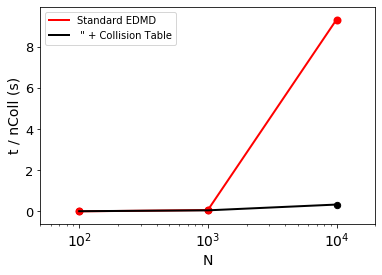

In [9]:
########### Execution time per collision #########
plt.plot(npart, totRunTime2*10**(-6)/nColl2, color='r', linewidth=2, label='Standard EDMD')
plt.plot(npart, totRunTime*10**(-6)/nColl, color='k', linewidth=2, label= ' " + Collision Table')

plt.scatter(npart, totRunTime*10**(-6)/nColl, color='k', s=40)
plt.scatter(npart, totRunTime2*10**(-6)/nColl2, color='r', linewidth=2)
plt.xlabel('N', fontsize = 14, color = 'k')
plt.ylabel('t / nColl (s)', fontsize = 14, color = 'k')
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 13)
plt.xscale('log')
plt.xlim(50, 2*10e+3)
plt.legend()
plt.savefig('ExecutionTimePerCollision.png', dpi=300)
plt.show()

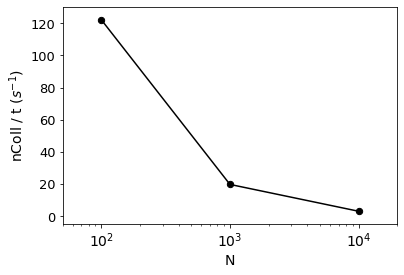

In [10]:
################## Plotting the number of collisions per second ##################
RunTimePerColl = totRunTime*10**(-6)/nColl
nCollPerSecond = np.array([])
for rt in RunTimePerColl:
    tmp = 1/rt
    nCollPerSecond = np.append(nCollPerSecond, tmp)


plt.plot(npart, nCollPerSecond, color='k')
plt.scatter(npart, nCollPerSecond, color='k', s=40)
plt.xlabel('N', fontsize = 14, color = 'k')
plt.ylabel(r'nColl / t ($s^{-1}$)', fontsize = 14, color = 'k')
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 13)
plt.xscale('log')
plt.xlim(50, 2*10e+3)
plt.savefig('noOfCollisionPerSecond.png', dpi=300)
plt.show()


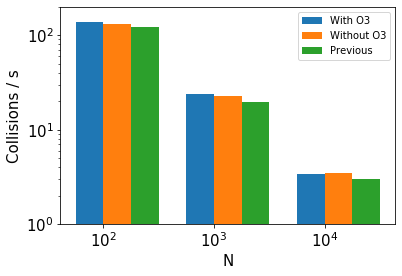

[137.64219471  23.94053233   3.40590939]


In [91]:
### Efficiency with o3 compilation ###
#TotRunTimeWithO3 = np.array([74473176, 425796201, 2984204369 ]) #Saving observables, global variable declearation.
#433728640
TotRunTimeWithO3 = np.array([72652140, 417701656, 2936073414 ])
TotRunTImeWithO3Run2 = np.array([146696423 806402530])
nColl2 = np.array([20000, 20000])

npartO3 = [100, 1000, 10000]
#TotRunTimeWithoutO3 = np.array([88881391, 469476042 ]) #Saving observables, global variable declearation.
TotRunTimeWithoutO3  = np.array([76545907, 444805705, 2910437244  ])
numColl = np.array([10000, 10000, 10000])

################## Plotting the number of collisions per second ##################
RunTimePerCollWithO3 = TotRunTimeWithO3*10**(-6)/numColl
RunTimePerCollWithoutO3 = TotRunTimeWithoutO3*10**(-6)/numColl

nCollPerSecondWithO3, nCollPerSecondWithoutO3 = np.array([]), np.array([])

for rt in range(len(npartO3)):
    tmp1 = 1/RunTimePerCollWithO3[rt]
    tmp2 = 1/RunTimePerCollWithoutO3[rt]
    nCollPerSecondWithO3 = np.append(nCollPerSecondWithO3, tmp1)
    nCollPerSecondWithoutO3 = np.append(nCollPerSecondWithoutO3, tmp2)

nCollPerSecondWithO3, nCollPerSecondWithoutO3 = np.array([]), np.array([])
RunTimePerCollWithO3Run2 = TotRunTimeWithO3Run2*10**(-6)/nColl2
for rt in range(len(nColl2)):
    tmp1 = 1/RunTimePerCollWithO3[rt]
    tmp2 = 1/RunTimePerCollWithoutO3[rt]
    nCollPerSecondWithO3 = np.append(nCollPerSecondWithO3, tmp1)
    nCollPerSecondWithoutO3 = np.append(nCollPerSecondWithoutO3, tmp2)
    
#plt.scatter(npartO3, nCollPerSecondWithO3, label='With O3')
#plt.scatter(npartO3, nCollPerSecondWithoutO3, label='Without O3')

#Creating the x-axis
barWidth=0.25
xval1 = np.arange(len(nCollPerSecondWithO3))
xval2 = [x + barWidth for x in xval1]
xval3 = [x + barWidth for x in xval2]

npartO3Str = [r'$10^2$', r'$10^3$', r'$10^4$']

plt.bar(xval1, nCollPerSecondWithO3, width=barWidth, label='With O3')
plt.bar(xval2, nCollPerSecondWithoutO3, width=barWidth, label='Without O3')
plt.bar(xval3, nCollPerSecond, width=barWidth, label = 'Previous')

#plt.legend()
plt.xlabel('N', fontsize = 15, color = 'k')
plt.ylabel('Collisions / s', fontsize = 15, color = 'k')
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.xticks([r + 0.5*barWidth for r in range(len(nCollPerSecondWithO3))], npartO3Str)

#plt.xscale('log')
plt.yscale('log')
plt.ylim(1, 2*10e+1)
plt.legend()
#plt.savefig('collisionsPerSecond.png', dpi=300)
plt.show()
print(nCollPerSecondWithO3)

In [9]:
### Calculating the collision frequency there using o3 there June 16  ###
# Here I am removing the map container list from the images only and it is increasing the efficiency by 10 times.
npart = [100, 1000, 10000, 100000]
TotRunTimeWithO3 = np.array([72652140, 417701656, 2936073414, 52319202357 ])*10**(-6) #This is the previous one for 10000 collisions.

TotRunTimeWithO3Run2 = np.array([146696423, 806402530, 5450271045,71069058082 ])*10**(-6) #Today June 16.
TotRunTimeWithO3Run3 = np.array([40308575, 224960116, 1472919914, 20577661568])*10**(-6) #Removing the automatic sorting predefined fun in imgFun calcualtion.
TotRunTimeWithO3Run4 = np.array([86882740, 460449268, 2809797807, 30667307827 ])*10**(-6)
nColl2 = np.array([20000, 20000, 20000, 20000])
nColl4 = np.array([40000, 40000, 40000, 40000])


collFreq2 = nColl2/TotRunTimeWithO3Run2 #Number of collisions per second.
collFreq3 = nColl2/TotRunTimeWithO3Run3
collFreq4 = nColl4/TotRunTimeWithO3Run4

print('collFreq2',collFreq2)
print('collFreq3', collFreq3)
print('collFreq4', collFreq4)
#print('TotRunTimeWithO3Run4: ', TotRunTimeWithO3Run4)

collFreq2 [136.33597596  24.80150949   3.66954227   0.28141642]
collFreq3 [496.1723405   88.90464832  13.57847077   0.97192774]
collFreq4 [460.39063685  86.87167682  14.23589979   1.30432056]


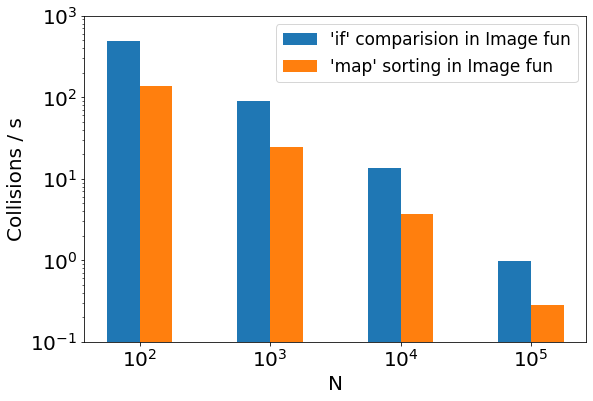

In [39]:
### Plotting the comparision when the map is removed from the imgSeq sorting in the image function calc. ###
import numpy as np
import matplotlib.pyplot as plt

npart = np.array([100, 1000, 10000, 100000])
TotRunTimeWithO3Run2 = np.array([146696423, 806402530, 5450271045, 71069058082])*10**(-6) #With the map in imgFun
TotRunTimeWithO3Run3 = np.array([40308575, 224960116, 1472919914, 20577661568])*10**(-6) #Without map in imgFun, with if.

nColl20k = np.array([20000, 20000, 20000, 20000])

collPerSecWithO3Run2 = nColl20k/TotRunTimeWithO3Run2
collPerSecWithO3Run3 = nColl20k/TotRunTimeWithO3Run3

##### Plotting ######

#Creating the x-axis
barWidth=0.25
xval1 = np.arange(len(nColl20k))
xval2 = [x + barWidth for x in xval1]
#xval3 = [x + barWidth for x in xval2]

npartO3Str = [r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$']
plt.figure(figsize=(9, 6))

siz = 20
plt.bar(xval1, collPerSecWithO3Run3, width=barWidth, label='\'if\' comparision in Image fun' )
plt.bar(xval2, collPerSecWithO3Run2, width=barWidth, label='\'map\' sorting in Image fun')

#plt.legend()
plt.xlabel('N', fontsize = siz, color = 'k')
plt.ylabel('Collisions / s', fontsize = siz, color = 'k')
plt.xticks(fontsize = siz)
plt.yticks(fontsize = siz)
plt.xticks([r + 0.5*barWidth for r in range(len(nColl20k))], npartO3Str)

#plt.xscale('log')
plt.yscale('log')
plt.ylim(0.1, 1*10e+2)
plt.legend(fontsize = siz-3)
plt.savefig('map_if_comparision_collisionsPerSecond.png', dpi=300)
plt.show()


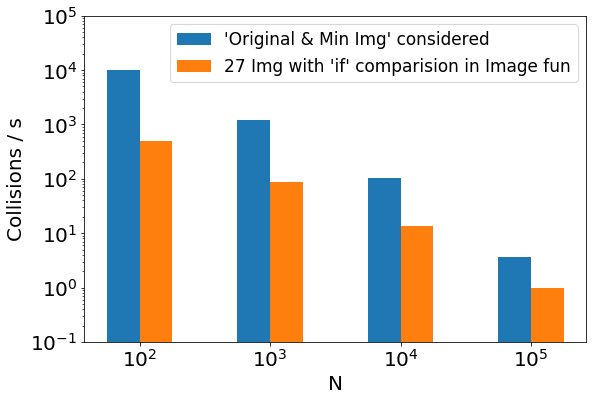

In [46]:
# Remove the image calculation over all the particles, consider only the original and the minimum image distances
# and find the collision time. The minimum of it is taken as the minimum collision time. This is expected to be valid
# for the large number of the particles and at the high packing fraction. June 17
import numpy as np
import matplotlib.pyplot as plt

npart = np.array([100, 1000, 10000, 100000])
TotRunTimeWithO3Run3 = np.array([40308575, 224960116, 1472919914, 20577661568])*10**(-6) #Without map in imgFun, with if
TotRunTimeWithoutImgFun = np.array([1989233, 16273007, 189567560, 5460966038])*10**(-6) #With original and the minimum image.
nColl20k = np.array([20000, 20000, 20000, 20000])


collPerSecWithO3Run3 = nColl20k/TotRunTimeWithO3Run3
collPerSecWithoutImgFun = nColl20k/TotRunTimeWithoutImgFun

##### Plotting ######

#Creating the x-axis
barWidth=0.25
xval1 = np.arange(len(nColl20k))
xval2 = [x + barWidth for x in xval1]
#xval3 = [x + barWidth for x in xval2]

npartO3Str = [r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$']
plt.figure(figsize=(9, 6))

siz = 20
plt.bar(xval1, collPerSecWithoutImgFun, width=barWidth, label='\'Original & Min Img\' considered' )
plt.bar(xval2, collPerSecWithO3Run3, width=barWidth, label='27 Img with \'if\' comparision in Image fun' )


#plt.legend()
plt.xlabel('N', fontsize = siz, color = 'k')
plt.ylabel('Collisions / s', fontsize = siz, color = 'k')
plt.xticks(fontsize = siz)
plt.yticks(fontsize = siz)
plt.xticks([r + 0.5*barWidth for r in range(len(nColl20k))], npartO3Str)

#plt.xscale('log')
plt.yscale('log')
plt.ylim(0.1, 1*10e+4)
plt.legend(fontsize = siz-3)
plt.savefig('originalAndMinImg_vs_ifComparisionInImgFun_comparision_collisionsPerSecond.png', dpi=300)
plt.show()



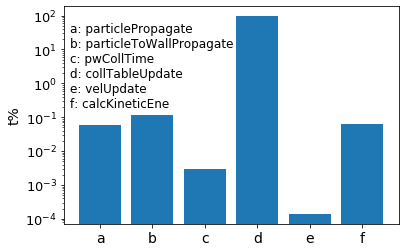

In [10]:
############# Plotting the time spent data ###########

################ Efficiency calculations of the code. #####################
npart = np.array([100, 1000, 10000])
nColl = np.array([10000,10000,100000 ])
### Time in microseconds ###
totRunTime = np.array([81823112,507196405, 33132552702  ])
particlePropagateT = np.array([10512,188736,1.92338e+07 ])
ParticleToWallPropagateT = np.array([151643, 848375, 3.99132e+07 ])
pwCollTimeT = np.array([221033, 154511,965954  ])
ppCollTimeT = np.array([7.05478e+07,4.46762e+08, 2.9137e+10  ])
collTableUpdateT = np.array([8.02668e+07, 4.92762e+08,3.17436e+10 ])
velUpdateT = np.array([4135,3730, 46402 ])
calcKineticEneT = np.array([10433, 191947,2.04545e+07 ])

execTime1 = np.array([particlePropagateT[-1], ParticleToWallPropagateT[-1], pwCollTimeT[-1], collTableUpdateT[-1], velUpdateT[-1], calcKineticEneT[-1] ])
execTime2 = (execTime1/totRunTime[-1])*100

labelsD = ['particlePropagate', 'particleToWallPropagate', 'pwCollTime', 'collTableUpdate', 'velUpdate', 'calcKineticEne']
labels = ['a', 'b', 'c', 'd', 'e', 'f']
txt = "a: particlePropagate\nb: particleToWallPropagate\nc: pwCollTime\nd: collTableUpdate\ne: velUpdate\nf: calcKineticEne"


plt.bar(labels, execTime2 )
#plt.legend()
plt.yscale('log')
#plt.xlabel('', fontsize = 14, color = 'k')
plt.ylabel('t%', fontsize = 14, color = 'k')
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 13)

plt.text(-0.58,0.2, txt, fontsize=12)
plt.savefig('PercentageOfTimeSpentInDiffFunctions.png', dpi=300)
plt.show()

In [10]:
def distFun(x1, x2):
    x12 = x1 - x2
    x12sq = np.dot(x12, x12)
    print(x12sq)


In [11]:
x6 = np.array([-2.02697, -8.68233, 2.21405])
x0 = np.array([-2.76032, -7.90482, 1.93043])
distFun(x6, x0)

x3 = np.array([0.575081, 8.42429, 3.7669])
x2 = np.array([1.52141, 8.68233, 4.40828])
distFun(x3, x2)

x9  =  np.array([1.21189, -6.56257, 3.03145])
x18 =  np.array([0.362072,-6.01018, 2.56537])
distFun(x18, x9)

1.2227643270000008
1.373491522241001
1.2445559116239997


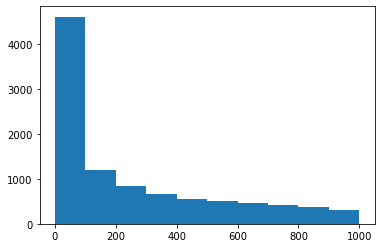

[   1.            1.1513954     1.32571137    1.52641797    1.75751062
    2.02358965    2.32995181    2.6826958     3.0888436     3.55648031
    4.09491506    4.71486636    5.42867544    6.25055193    7.19685673
    8.28642773    9.54095476   10.98541142   12.64855217   14.56348478
   16.76832937   19.30697729   22.22996483   25.59547923   29.47051703
   33.93221772   39.06939937   44.98432669   51.79474679   59.63623317
   68.6648845    79.06043211   91.0298178   104.81131342  120.67926406
  138.94954944  159.98587196  184.20699693  212.09508879  244.20530945
  281.1768698   323.74575428  372.75937203  429.19342601  494.17133613
  568.9866029   655.12855686  754.31200634  868.51137375 1000.        ]
(array([ 56,  44,  54,  51,  61,  61,  56,  59,  90,  79,  61,  78,  87,
        91,  86,  92,  89, 100, 126, 122, 109, 136, 118, 134, 172, 152,
       165, 134, 191, 178, 177, 222, 241, 213, 249, 235, 254, 286, 279,
       278, 337, 333, 333, 361, 401, 419, 447, 436, 438]), array([   1. 

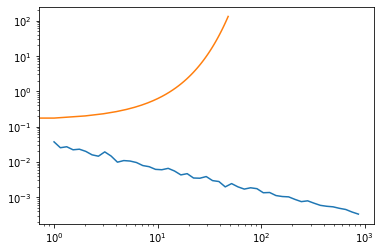

In [12]:
###### Histogram binnings ######
import numpy as np
from matplotlib import pyplot as plt

# something random to plot
data = (np.random.random(10000)*10)**3

plt.hist(data)
plt.show()

# log-scaled bins
bins = np.logspace(0, 3, 50)
print(bins)

widths = (bins[1:] - bins[:-1])

# Calculate histogram
hist = np.histogram(data, bins=bins)

print(hist)
print(len(hist[0]))

print(len(hist[1]))
# normalize by bin width
hist_norm = hist[0]/widths
hist_norm = hist_norm/len(data)

# plot it!
plt.plot(bins[:-1], hist_norm, widths)
plt.xscale('log')
plt.yscale('log')
plt.show()

In [23]:
a = 0.03562275
b = [10**a, 10**(2*a)]

print(b)
#Difference between the two numbers.

print(b[1] - b[0])

[1.0854823095175357, 1.1782718442755233]
0.09278953475798768


In [26]:
c = 10**(0.06) - 10**(0.12)
print(c)

-0.1701031170595242
